# Funktionen mehrerer Veränderlicher II: Konvergenz, Grenzwerte und Stetigkeit

**Begleit-Notebook zum Vorlesungsskript „Angewandte Mathematik – 2. Funktionen mehrerer Veränderlicher“ (Abschnitte 2.2 und 2.3)**

Das Notebook folgt der Gliederung des Skripts. Definitionen, Sätze und Beispiele tragen dieselbe Nummer wie im Skript. Zu den Beispielen gibt es

* den Rechenweg aus dem Skript in Formeln,
* eine **Probe mit SymPy** (das Residuum muss 0 sein),
* eine **Grafik** und an einigen Stellen ein **interaktives Element** (Schieberegler),
* am Ende **Übungsaufgaben** mit aufklappbarer Musterlösung und einer prüfenden Codezelle.

**Voraussetzungen:** `numpy`, `sympy`, `matplotlib`, `ipywidgets`
**Arbeitsweise:** Zellen der Reihe nach ausführen und die Kontrollausgaben prüfen.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/funktionen_mehrerer_veraenderlicher/02_konvergenz_grenzwerte_stetigkeit.ipynb)

**Inhalt**


1. Abschnitt 2.2: Konvergenz im $\mathbb{R}^n$ (Definition 2.2.1, Beispiele 2.2.2 und 2.2.3)
2. Abschnitt 2.3: Grenzwerte von Funktionen (Definition 2.3.1, Beispiel 2.3.2)
3. Stetigkeit: $\varepsilon$-$\delta$-Definition 2.3.3, Folgenkriterium 2.3.4, Rechenregeln 2.3.5
4. Unstetige Funktionen: Beispiele 2.3.7 und 2.3.8, Annäherung auf verschiedenen Wegen
5. Vektorwertige Funktionen (Definition 2.3.9, Satz 2.3.10, Beispiel 2.3.11)
6. Innere Punkte und Randpunkte (Definition 2.3.12)
7. Übungen

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
from matplotlib import cm
plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})
sp.init_printing()

x, y, z = sp.symbols('x y z', real=True)
ROT, BLAU = '#d71920', '#0b5cad'


def pruefe(name, residuum):
    """Vereinfacht ein Residuum, gibt es aus und bricht ab, falls es nicht 0 ist."""
    r = sp.simplify(residuum)
    if isinstance(r, sp.MatrixBase):
        ok = all(sp.simplify(e) == 0 for e in r)
    else:
        ok = r == 0
    print(f'Probe {name}: Residuum = {r}  ->', 'ok' if ok else 'FEHLER')
    assert ok


def flaeche(f, xbereich, ybereich, n=60, ax=None, titel=None, cmap='YlOrBr_r', alpha=1.0, blick=(30, -60)):
    """Zeichnet z = f(x, y) als Fläche (f als NumPy-Funktion). Gibt die Achse zurück."""
    if ax is None:
        fig = plt.figure(figsize=(7, 5))
        ax = fig.add_subplot(projection='3d')
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    ax.plot_surface(X, Y, Z, cmap=cmap, alpha=alpha, linewidth=0.2, edgecolor=(0.3, 0.15, 0, 0.3),
                    rstride=max(1, n // 30), cstride=max(1, n // 30))
    ax.set(xlabel='x', ylabel='y', zlabel='z')
    ax.view_init(*blick)
    if titel:
        ax.set_title(titel)
    return ax


def hoehenlinien(f, xbereich, ybereich, n=300, ax=None, niveaus=12, titel=None, gefuellt=True):
    """Zeichnet die Höhenlinien f(x, y) = c (optional eingefärbt). Gibt die Achse zurück."""
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    if gefuellt:
        cf = ax.contourf(X, Y, Z, levels=niveaus, cmap='YlOrBr_r', extend='both')
        plt.colorbar(cf, ax=ax, shrink=0.85)
    cs = ax.contour(X, Y, Z, levels=niveaus, colors='0.25', linewidths=0.7)
    ax.clabel(cs, fontsize=7, fmt='%.2g')
    ax.set(xlabel='x', ylabel='y', aspect='equal')
    if titel:
        ax.set_title(titel)
    return ax


n, k = sp.symbols('n k', positive=True, integer=True)

## 1. Abschnitt 2.2: Konvergenz im $\mathbb{R}^n$

Der Betrag $\|a\| = \sqrt{a_1^2 + \dots + a_n^2}$ liefert einen Abstandsbegriff im $\mathbb{R}^n$. Damit lässt sich der Grenzwertbegriff aus einer Variablen direkt übertragen.

### Definition 2.2.1 (Grenzwert)

Eine Folge von Vektoren $(x_k)_{k=1}^{\infty}$ im $\mathbb{R}^n$ heißt **konvergent** zum Grenzwert $x_0\in\mathbb{R}^n$, falls der Abstand gegen Null geht:
$$\lim_{k\to\infty}x_k = x_0 \iff \lim_{k\to\infty}\|x_k - x_0\| = 0.$$

**Bemerkung:** Das ist gleichbedeutend damit, dass **jede Komponente** von $x_k$ gegen die entsprechende Komponente von $x_0$ konvergiert. Grund: $|x_{k,i} - x_{0,i}|\le\|x_k - x_0\|\le\sqrt{n}\,\max_i|x_{k,i} - x_{0,i}|$.

### Beispiel 2.2.2

Im $\mathbb{R}^2$ sei $x_n = \left(\dfrac1n,\ \dfrac{n-1}{n+1}\right)$. Koordinatenweise:
$$x_0 = \left(\lim_{n\to\infty}\frac1n,\ \lim_{n\to\infty}\frac{n-1}{n+1}\right) = (0, 1).$$
Abstand zum Grenzwert:
$$\|x_n - x_0\| = \sqrt{\frac{1}{n^2} + \frac{4}{(n+1)^2}} < \frac{\sqrt5}{n}\ \longrightarrow\ 0.$$

     ⎡0⎤
x₀ = ⎢ ⎥
     ⎣1⎦

Probe Abstand² - (1/n² + 4/(n+1)²): Residuum = 0  -> ok
5/n² - Abstand² = 4*(2*n + 1)/(n**2*(n + 1)**2)  > 0 für alle n ≥ 1


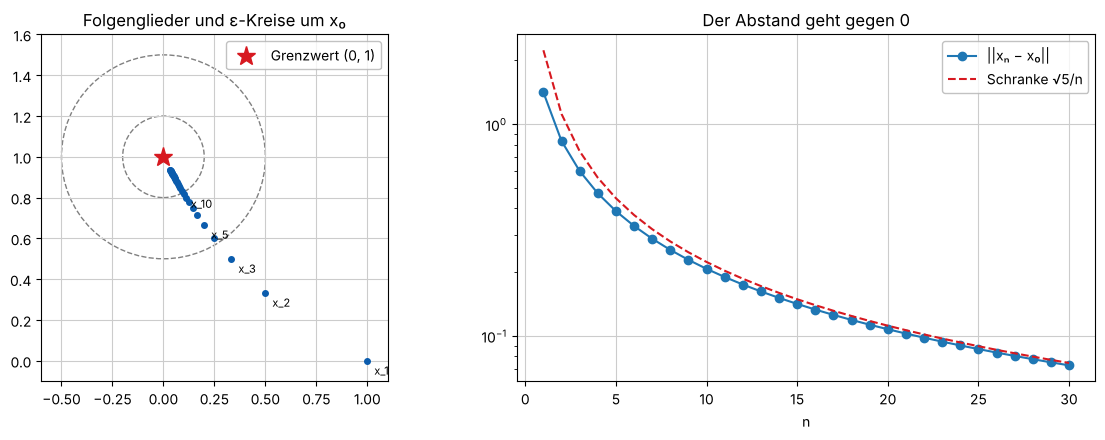

In [2]:
xn = sp.Matrix([1/n, (n - 1)/(n + 1)])
x0 = sp.Matrix([sp.limit(e, n, sp.oo) for e in xn])
display(sp.Eq(sp.Symbol('x_0'), x0, evaluate=False))
abstand = sp.sqrt(sum((xn - x0).applyfunc(lambda e: e**2)))
pruefe('Abstand² - (1/n² + 4/(n+1)²)', abstand**2 - (1/n**2 + 4/(n + 1)**2))
print('5/n² - Abstand² =', sp.factor(sp.simplify(5/n**2 - abstand**2)), ' > 0 für alle n ≥ 1')

N = np.arange(1, 31)
punkte = np.array([[1/m, (m - 1)/(m + 1)] for m in N])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(punkte[:, 0], punkte[:, 1], 'o', color=BLAU, markersize=4)
for m in (1, 2, 3, 5, 10):
    ax1.annotate(f'x_{m}', punkte[m - 1], textcoords='offset points', xytext=(5, -10), fontsize=8)
ax1.plot(0, 1, '*', color=ROT, markersize=14, label='Grenzwert (0, 1)')
for eps in (0.5, 0.2):
    ax1.add_patch(plt.Circle((0, 1), eps, fill=False, linestyle='--', color='0.5'))
ax1.set(aspect='equal', xlim=(-0.6, 1.1), ylim=(-0.1, 1.6), title='Folgenglieder und ε-Kreise um x₀'); ax1.legend()
ax2.semilogy(N, [float(abstand.subs(n, m)) for m in N], 'o-', label='||xₙ − x₀||')
ax2.semilogy(N, np.sqrt(5)/N, '--', color=ROT, label='Schranke √5/n')
ax2.set(xlabel='n', title='Der Abstand geht gegen 0'); ax2.legend()
plt.tight_layout(); plt.show()

### Beispiel 2.2.3

Berechnen Sie die Grenzwerte der Folgen
$$\text{(a)}\ x_k = \begin{pmatrix}1 - \frac1k\\[2pt] \frac{2k}{k+1}\end{pmatrix},\qquad \text{(b)}\ x_k = \begin{pmatrix}\frac1k\\[2pt] \frac{k^2}{k+1}\end{pmatrix}.$$

**(a)** koordinatenweise $\to(1, 2)$. **(b)** Die erste Komponente konvergiert gegen 0, die zweite divergiert. Damit divergiert die Folge.

In [3]:
for name, folge in (('(a)', [1 - 1/k, 2*k/(k + 1)]), ('(b)', [1/k, k**2/(k + 1)])):
    print(name, [sp.limit(e, k, sp.oo) for e in folge])

(a) [1, 2]
(b) [0, oo]


## 2. Abschnitt 2.3: Grenzwerte von Funktionen

### Definition 2.3.1

Es sei $f:D\subseteq\mathbb{R}^n\to\mathbb{R}$. Der Punkt $y_0\in\mathbb{R}$ heißt **Grenzwert von $f$ an der Stelle $x_0$**, wenn für **jede** Folge $(x_k)$ in $D$ mit $x_k\ne x_0$ und $x_k\to x_0$ auch $f(x_k)\to y_0$ gilt. Schreibweise: $\lim_{x\to x_0}f(x) = y_0$.

Das Wort **jede** ist entscheidend: Im $\mathbb{R}^2$ kann man sich einem Punkt aus unendlich vielen Richtungen und auf beliebig verschlungenen Wegen nähern. In einer Variablen gibt es nur „von links“ und „von rechts“.

### Beispiel 2.3.2

$$\lim_{x\to(0,2)}\frac{x_2\sin(x_1)}{x_1}.$$
Wenn $x\to(0,2)$, dann $x_1\to 0$ und $x_2\to 2$. Wegen $\lim_{x_1\to 0}\frac{\sin x_1}{x_1} = 1$ und $\lim_{x_2\to 2}x_2 = 2$ folgt
$$\lim_{x\to(0,2)}\frac{x_2\sin(x_1)}{x_1} = 2\cdot 1 = 2.$$
Die Funktion ist für $x_1 = 0$ nicht definiert, der Grenzwert existiert aber.

Taylor: sin(x1)/x1 = 1 - x1**2/6 + x1**4/120 + O(x1**6)
Grenzwert entlang verschiedener Wege nach (0, 2):
   x1 = s, x2 = 2         -> 2
   x1 = s, x2 = 2 + s     -> 2
   x1 = s², x2 = 2 − s    -> 2


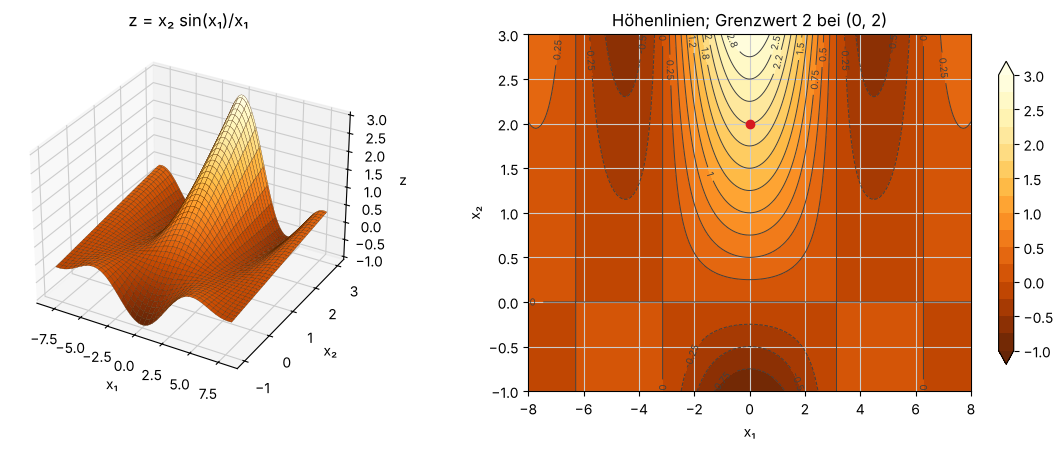

In [4]:
x1, x2 = sp.symbols('x1 x2', real=True)
f232 = x2*sp.sin(x1)/x1
print('Taylor: sin(x1)/x1 =', sp.series(sp.sin(x1)/x1, x1, 0, 6))
print('Grenzwert entlang verschiedener Wege nach (0, 2):')
s = sp.symbols('s', positive=True)
for weg, (w1, w2) in {'x1 = s, x2 = 2': (s, 2), 'x1 = s, x2 = 2 + s': (s, 2 + s), 'x1 = s², x2 = 2 − s': (s**2, 2 - s)}.items():
    print(f'   {weg:22s} ->', sp.limit(f232.subs({x1: w1, x2: w2}), s, 0))

f232_num = lambda X1, X2: X2*np.sinc(X1/np.pi)          # np.sinc(t) = sin(πt)/(πt), stetig fortgesetzt
fig = plt.figure(figsize=(12, 4.6))
ax = fig.add_subplot(1, 2, 1, projection='3d')
flaeche(f232_num, (-8, 8), (-1, 3), n=80, ax=ax, titel='z = x₂ sin(x₁)/x₁')
ax.plot([0], [2], [2], 'o', color=ROT, markersize=6); ax.set(xlabel='x₁', ylabel='x₂')
ax2 = fig.add_subplot(1, 2, 2)
hoehenlinien(f232_num, (-8, 8), (-1, 3), ax=ax2, niveaus=np.linspace(-1, 3, 17), titel='Höhenlinien; Grenzwert 2 bei (0, 2)')
ax2.plot(0, 2, 'o', color=ROT); ax2.set(xlabel='x₁', ylabel='x₂', aspect='auto')
plt.tight_layout(); plt.show()

## 3. Stetigkeit

### Definition 2.3.3 (Stetigkeit)

$f:D\subseteq\mathbb{R}^n\to\mathbb{R}$ heißt **stetig an der Stelle** $x_0\in D$, wenn es zu jedem $\varepsilon > 0$ ein $\delta(\varepsilon) > 0$ gibt, so dass für alle $x\in D$ gilt:
$$\|x - x_0\| < \delta(\varepsilon)\ \Longrightarrow\ |f(x) - f(x_0)| < \varepsilon.$$
Gilt das für alle $x_0\in D$, heißt $f$ **stetig**. Die Menge der stetigen Funktionen auf $D$ heißt $C(D)$ oder $C^0(D)$.

**Anschaulich:** Gibt man eine Toleranz $\varepsilon$ für die Funktionswerte vor, findet man einen Kreis (eine Kugel) vom Radius $\delta$ um $x_0$, auf dem $f$ innerhalb des $\varepsilon$-Bandes bleibt.

**Interaktiv:** Für $f(x,y) = x^2 + y^2$ im Punkt $x_0 = (1, 0.5)$ wird zu gewähltem $\varepsilon$ das größte passende $\delta$ numerisch bestimmt. Grün ist der Bereich, in dem $|f - f(x_0)| < \varepsilon$ gilt; der $\delta$-Kreis muss ganz hineinpassen.

FloatSlider(value=0.5, continuous_update=False, description='ε', max=1.5, min=0.05, step=0.05)

Output()

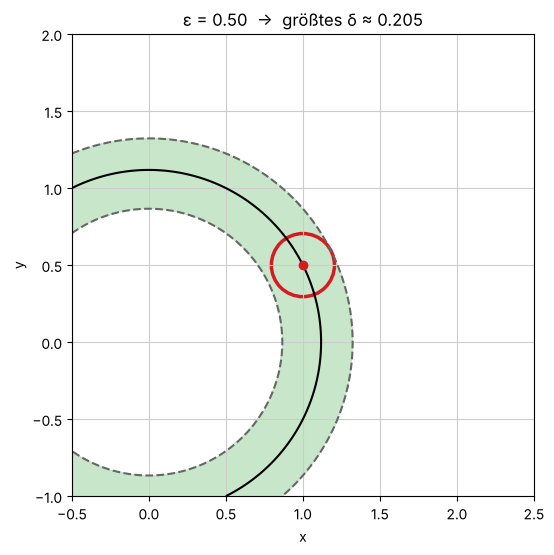

In [5]:
f_st = lambda X, Y: X**2 + Y**2
P0 = np.array([1.0, 0.5])


def groesstes_delta(eps, f=f_st, p=P0):
    """Größtes δ, so dass |f - f(p)| < ε auf der ganzen δ-Kreisscheibe gilt (Bisektion)."""
    phi = np.linspace(0, 2*np.pi, 721)
    def passt(d):
        r = np.linspace(0, d, 40)[:, None]
        return np.max(np.abs(f(p[0] + r*np.cos(phi), p[1] + r*np.sin(phi)) - f(*p))) < eps
    lo, hi = 0.0, 2.0
    for _ in range(30):
        mid = (lo + hi)/2
        lo, hi = (mid, hi) if passt(mid) else (lo, mid)
    return lo


def zeige_eps_delta(eps=0.5):
    d = groesstes_delta(eps)
    X, Y = np.meshgrid(np.linspace(-0.5, 2.5, 400), np.linspace(-1, 2, 400))
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.contourf(X, Y, (np.abs(f_st(X, Y) - f_st(*P0)) < eps).astype(float), levels=[0.5, 1.5], colors=['#c8e6c9'])
    ax.contour(X, Y, f_st(X, Y), levels=[f_st(*P0) - eps, f_st(*P0), f_st(*P0) + eps], colors=['0.4', 'black', '0.4'],
               linestyles=['--', '-', '--'])
    ax.add_patch(plt.Circle(P0, d, fill=False, color=ROT, linewidth=2.5))
    ax.plot(*P0, 'o', color=ROT)
    ax.set(aspect='equal', xlabel='x', ylabel='y', title=f'ε = {eps:.2f}  →  größtes δ ≈ {d:.3f}')
    plt.show()


eps_r = widgets.FloatSlider(value=0.5, min=0.05, max=1.5, step=0.05, description='ε', continuous_update=False)
display(eps_r, widgets.interactive_output(zeige_eps_delta, {'eps': eps_r}))

# Statische Vorschau für GitHub.
zeige_eps_delta()

### Satz 2.3.4 (Folgenkriterium)

$f$ ist genau dann stetig in $x_0\in D$, wenn für **jede** Folge $(x_n)$ in $D$ mit $x_n\to x_0$ gilt: $\lim_{n\to\infty}f(x_n) = f(x_0)$.

### Satz 2.3.5 (Rechenregeln)

(a) Summe, Produkt und Quotient (Nenner $\ne 0$) stetiger Funktionen sind stetig.
(b) Verkettungen stetiger Funktionen sind stetig.

### Beispiel 2.3.6

$f(x,y) = x^2 + y^2$ ist auf ganz $\mathbb{R}^2$ stetig, denn es ist aus den stetigen Funktionen $f_1(x,y) = x$ und $f_2(x,y) = y$ durch Produkte und Summen zusammengesetzt. Mit denselben Regeln sind alle Polynome in $x$ und $y$, aber auch Funktionen wie $e^{-x^2-y^2}$, $\sin(xy)$ oder $\frac{x}{1 + y^2}$ stetig.

## 4. Unstetige Funktionen

### Beispiel 2.3.7

$$f(x,y) = \begin{cases}1, & \text{falls } x^2 = y \text{ und } x > 0,\\ 0, & \text{sonst}\end{cases}$$
ist unstetig in $(0,0)$: Die Punkte $\left(\frac1n, \frac{1}{n^2}\right)$ liegen auf der Parabel und konvergieren gegen $(0,0)$, aber $f\left(\frac1n, \frac{1}{n^2}\right) = 1\ne 0 = f(0,0)$. Entlang der $x$-Achse dagegen ist $f = 0$.

Dieses Beispiel zeigt, dass es **nicht** genügt, nur geradlinige Annäherungen zu prüfen: Auf **jeder** Geraden durch den Ursprung ist $f = 0$ in der Nähe von $(0,0)$ (eine Gerade schneidet die Parabel höchstens in einem weiteren Punkt).

 n   f(1/n, 1/n²)   f(1/n, 0)   f(1/n, 1/n)
 1            1           0            1
 2            1           0            0
 3            1           0            0
 4            1           0            0
 5            1           0            0
 6            1           0            0
 7            1           0            0
 8            1           0            0
Hinweis: (1, 1) liegt selbst auf der Parabel; das ist der einzige weitere Schnittpunkt der Geraden y = x mit y = x².


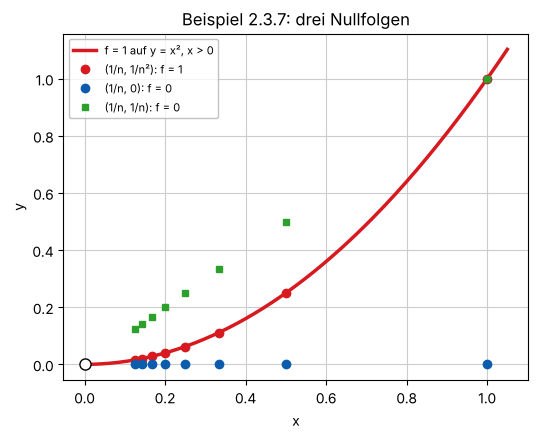

In [6]:
def f237(xx, yy):
    return 1.0 if (xx > 0 and abs(xx**2 - yy) < 1e-14) else 0.0

N = np.arange(1, 9)
print(' n   f(1/n, 1/n²)   f(1/n, 0)   f(1/n, 1/n)')
for m in N:
    print(f'{m:2d}   {f237(1/m, 1/m**2):10.0f}   {f237(1/m, 0):9.0f}   {f237(1/m, 1/m):10.0f}')
print('Hinweis: (1, 1) liegt selbst auf der Parabel; das ist der einzige weitere Schnittpunkt der Geraden y = x mit y = x².')

fig, ax = plt.subplots(figsize=(6, 4.5))
xs = np.linspace(0.001, 1.05, 200)
ax.plot(xs, xs**2, color=ROT, linewidth=2.5, label='f = 1 auf y = x², x > 0')
ax.plot(1/N, 1/N**2, 'o', color=ROT, label='(1/n, 1/n²): f = 1')
ax.plot(1/N, 0*N, 'o', color=BLAU, label='(1/n, 0): f = 0')
ax.plot(1/N, 1/N, 's', color='C2', markersize=4, label='(1/n, 1/n): f = 0')
ax.plot(0, 0, 'o', mfc='white', mec='black', markersize=8)
ax.set(xlabel='x', ylabel='y', title='Beispiel 2.3.7: drei Nullfolgen'); ax.legend(fontsize=8)
plt.show()

### Beispiel 2.3.8

$$f(x,y) = \begin{cases}\sin\dfrac{1}{x^2 + y^2}, & (x,y)\ne(0,0),\\ 0, & (x,y) = (0,0)\end{cases}$$
ist unstetig in $(0,0)$: Für $(x_n, y_n) = \left(\frac{1}{\sqrt{2\pi n}}, 0\right)$ ist $f = \sin(2\pi n) = 0$, für $(x_n, y_n) = \left(\frac{1}{\sqrt{2\pi n + \pi/2}}, 0\right)$ ist $f = \sin(2\pi n + \frac{\pi}{2}) = 1$. Beide Folgen gehen gegen $(0,0)$, die Funktionswerte haben verschiedene Grenzwerte.

Mit $r^2 = x^2 + y^2$ hängt $f$ nur vom Abstand $r$ zum Ursprung ab: $f = \sin(1/r^2)$. Die Funktion schwingt für $r\to 0$ immer schneller zwischen $-1$ und $1$.

Probe Folge 1: f = 0: Residuum = 0  -> ok
Probe Folge 2: f - 1 = 0: Residuum = 0  -> ok


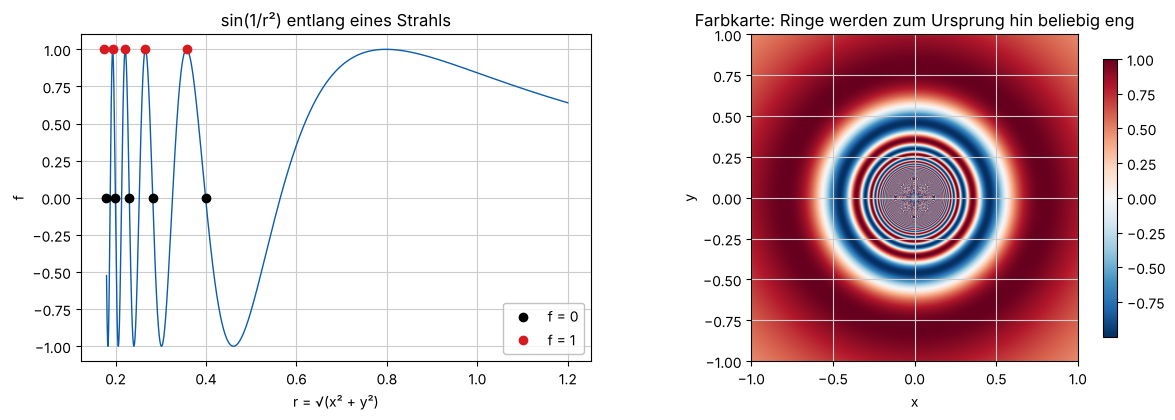

In [7]:
nn = sp.symbols('n', positive=True, integer=True)
f238 = sp.sin(1/(x**2 + y**2))
pruefe('Folge 1: f = 0', f238.subs({x: 1/sp.sqrt(2*sp.pi*nn), y: 0}))
pruefe('Folge 2: f - 1 = 0', f238.subs({x: 1/sp.sqrt(2*sp.pi*nn + sp.pi/2), y: 0}) - 1)

r = np.linspace(0.18, 1.2, 4000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.plot(r, np.sin(1/r**2), color=BLAU, linewidth=1)
m = np.arange(1, 6)
ax1.plot(1/np.sqrt(2*np.pi*m), 0*m, 'o', color='black', label='f = 0')
ax1.plot(1/np.sqrt(2*np.pi*m + np.pi/2), 0*m + 1, 'o', color=ROT, label='f = 1')
ax1.set(xlabel='r = √(x² + y²)', ylabel='f', title='sin(1/r²) entlang eines Strahls'); ax1.legend()
X, Y = np.meshgrid(np.linspace(-1, 1, 800), np.linspace(-1, 1, 800))
with np.errstate(divide='ignore'):
    im = ax2.imshow(np.sin(1/(X**2 + Y**2)), extent=(-1, 1, -1, 1), origin='lower', cmap='RdBu_r')
plt.colorbar(im, ax=ax2, shrink=0.85); ax2.set(title='Farbkarte: Ringe werden zum Ursprung hin beliebig eng', xlabel='x', ylabel='y')
plt.tight_layout(); plt.show()

### Annäherung auf verschiedenen Wegen: ein typisches Prüfungsbeispiel

Für
$$f(x,y) = \frac{x^2 y}{x^4 + y^2},\qquad f(0,0) = 0,$$
ist der Grenzwert entlang **jeder Geraden** $y = mx$ gleich 0, entlang der Parabel $y = x^2$ aber $\frac12$. Damit existiert $\lim_{(x,y)\to(0,0)}f(x,y)$ nicht, und $f$ ist in $(0,0)$ unstetig.

**Interaktiv:** Wählen Sie Wege $y = m\,x^p$. Rechts sieht man $f$ entlang des Weges als Funktion von $x$.

entlang y = m x  : 0
entlang y = m x² : m/(m**2 + 1) (konstant, abhängig von m)


Output()

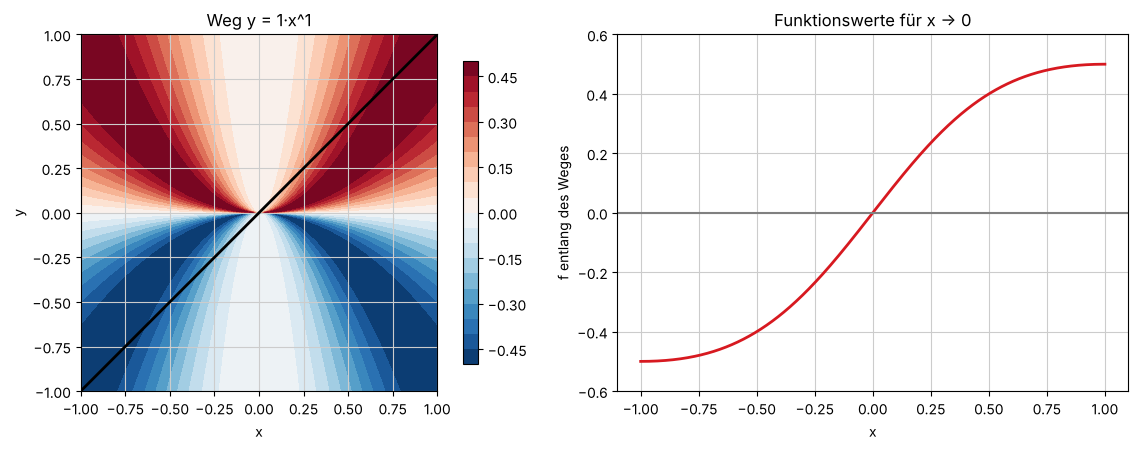

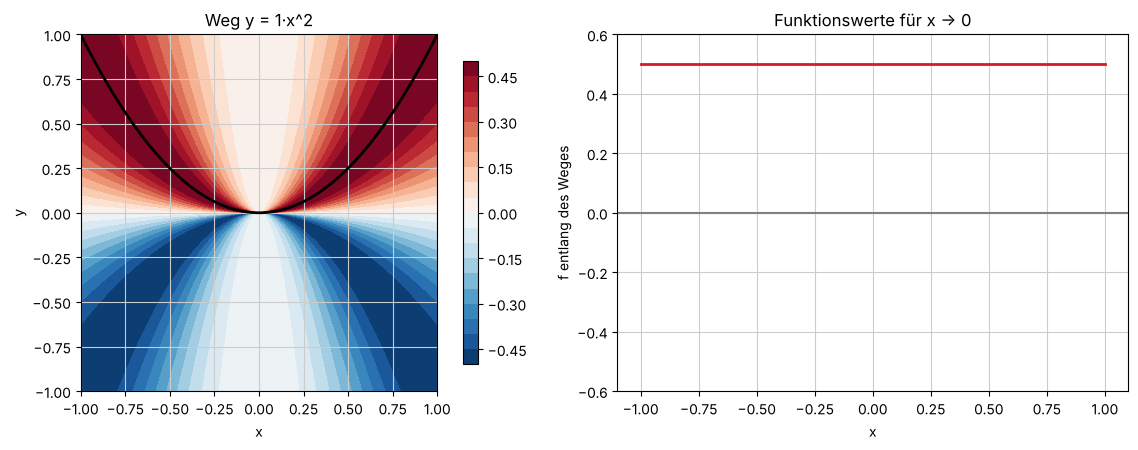

In [8]:
f_weg = x**2*y/(x**4 + y**2)
m_, p_ = sp.symbols('m p', real=True)
print('entlang y = m x  :', sp.limit(f_weg.subs(y, m_*x), x, 0))
print('entlang y = m x² :', sp.simplify(f_weg.subs(y, m_*x**2)), '(konstant, abhängig von m)')
f_weg_num = sp.lambdify((x, y), f_weg, 'numpy')


def zeige_weg(m=1.0, p=1.0):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
    X, Y = np.meshgrid(np.linspace(-1, 1, 500), np.linspace(-1, 1, 500))
    with np.errstate(invalid='ignore', divide='ignore'):
        cf = ax1.contourf(X, Y, f_weg_num(X, Y), levels=np.linspace(-0.5, 0.5, 21), cmap='RdBu_r')
    plt.colorbar(cf, ax=ax1, shrink=0.85)
    xs = np.linspace(-1, 1, 801); xs = xs[xs != 0]
    ys = m*xs**p if float(p).is_integer() else m*np.abs(xs)**p
    ax1.plot(xs, ys, color='black', linewidth=2)
    ax1.set(xlim=(-1, 1), ylim=(-1, 1), aspect='equal', title=f'Weg y = {m:g}·x^{p:g}', xlabel='x', ylabel='y')
    with np.errstate(invalid='ignore', divide='ignore'):
        ax2.plot(xs, f_weg_num(xs, ys), color=ROT, linewidth=2)
    ax2.axhline(0, color='0.5'); ax2.set(ylim=(-0.6, 0.6), xlabel='x', ylabel='f entlang des Weges', title='Funktionswerte für x → 0')
    plt.tight_layout(); plt.show()


m_r = widgets.FloatSlider(value=1.0, min=-3, max=3, step=0.25, description='m', continuous_update=False)
p_r = widgets.FloatSlider(value=1.0, min=1, max=3, step=0.5, description='p', continuous_update=False)
display(widgets.HBox([m_r, p_r]), widgets.interactive_output(zeige_weg, {'m': m_r, 'p': p_r}))

# Statische Vorschau für GitHub: Gerade und Parabel
zeige_weg(1.0, 1.0)
zeige_weg(1.0, 2.0)

**Merke:**

* Um zu zeigen, dass ein Grenzwert **nicht** existiert, genügen **zwei** Wege mit verschiedenen Grenzwerten.
* Um zu zeigen, dass er **existiert**, genügen Wege nicht. Ein bewährtes Mittel sind **Polarkoordinaten** $x = r\cos\varphi$, $y = r\sin\varphi$: Lässt sich $|f(x,y) - y_0|\le g(r)$ mit $g(r)\to 0$ abschätzen (unabhängig von $\varphi$), existiert der Grenzwert. Beispiel: $\left|\frac{x^2y}{x^2 + y^2}\right| = r\,|\cos^2\varphi\sin\varphi|\le r\to 0$.

## 5. Vektorwertige Funktionen

### Definition 2.3.9 und Satz 2.3.10

Für $f:D\subseteq\mathbb{R}^n\to\mathbb{R}^m$ werden Grenzwert und Stetigkeit genauso definiert, nur mit $\|f(x) - y_0\|$ im $\mathbb{R}^m$. Die Menge der stetigen Funktionen heißt $C(D,\mathbb{R}^m)$.

**Satz 2.3.10:** $f$ ist genau dann stetig in $x_0$, wenn jede Komponente $f_1,\dots,f_m$ in $x_0$ stetig ist.

### Beispiel 2.3.11

$$f(x) = \begin{pmatrix}f_1(x_1,x_2)\\ f_2(x_1,x_2)\end{pmatrix} = \begin{pmatrix}x_1 + x_2\\ \cos(x_1x_2)\end{pmatrix}$$
ist auf ganz $\mathbb{R}^2$ stetig: $f_1$ ist eine Summe stetiger Funktionen, $f_2$ eine Verkettung von $x_1x_2$ und $\cos$.

Eine vektorwertige Funktion $\mathbb{R}^2\to\mathbb{R}^2$ kann man als **Abbildung der Ebene** zeichnen: Ein Gitter wird in ein verzerrtes Gitter überführt. Bei einer stetigen Funktion reißt das Gitter nicht auf.

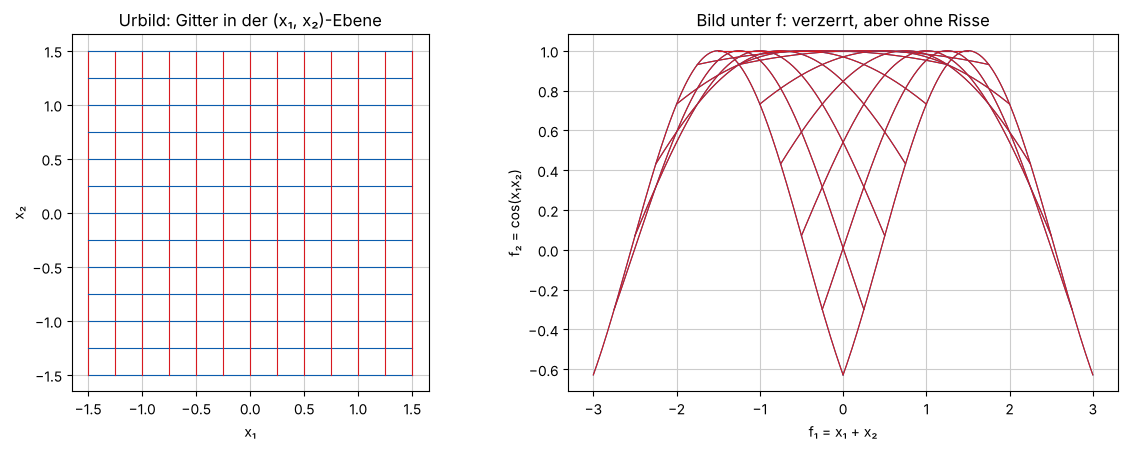

In [9]:
F2311 = lambda X1, X2: (X1 + X2, np.cos(X1*X2))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
werte = np.linspace(-1.5, 1.5, 13)
s = np.linspace(-1.5, 1.5, 200)
for c in werte:
    ax1.plot(s, 0*s + c, color=BLAU, linewidth=0.8); ax1.plot(0*s + c, s, color=ROT, linewidth=0.8)
    u1, u2 = F2311(s, 0*s + c); ax2.plot(u1, u2, color=BLAU, linewidth=0.8)
    v1, v2 = F2311(0*s + c, s); ax2.plot(v1, v2, color=ROT, linewidth=0.8)
ax1.set(aspect='equal', title='Urbild: Gitter in der (x₁, x₂)-Ebene', xlabel='x₁', ylabel='x₂')
ax2.set(title='Bild unter f: verzerrt, aber ohne Risse', xlabel='f₁ = x₁ + x₂', ylabel='f₂ = cos(x₁x₂)')
plt.tight_layout(); plt.show()

## 6. Definition 2.3.12: Innere Punkte und Randpunkte

Es sei $D\subseteq\mathbb{R}^n$. Ein Punkt $x\in D$ heißt **innerer Punkt** von $D$, wenn es ein $\varepsilon > 0$ gibt, so dass die $\varepsilon$-Umgebung
$$U_\varepsilon(x) = \{y\in\mathbb{R}^n:\ \|x - y\| < \varepsilon\}$$
ganz in $D$ liegt. Enthält jede $\varepsilon$-Umgebung von $x\in\mathbb{R}^n$ sowohl Punkte aus $D$ als auch Punkte, die nicht in $D$ liegen, heißt $x$ **Randpunkt** von $D$. Ein Randpunkt muss **nicht** zu $D$ gehören.

Partielle Ableitungen (Abschnitt 2.4) werden in inneren Punkten definiert: Dort kann man sich in jede Richtung ein Stück bewegen, ohne $D$ zu verlassen.

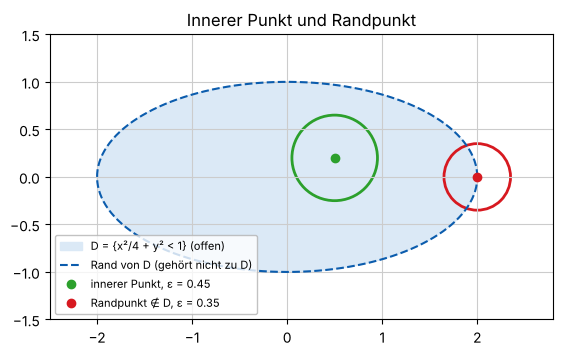

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5))
t = np.linspace(0, 2*np.pi, 300)
ax.fill(2*np.cos(t), np.sin(t), color='#dbe9f6', label='D = {x²/4 + y² < 1} (offen)')
ax.plot(2*np.cos(t), np.sin(t), '--', color=BLAU, label='Rand von D (gehört nicht zu D)')
for (px, py), eps, farbe, name in (((0.5, 0.2), 0.45, 'C2', 'innerer Punkt'), ((2.0, 0.0), 0.35, ROT, 'Randpunkt ∉ D')):
    ax.add_patch(plt.Circle((px, py), eps, fill=False, color=farbe, linewidth=2))
    ax.plot(px, py, 'o', color=farbe, label=f'{name}, ε = {eps}')
ax.set(aspect='equal', xlim=(-2.5, 2.8), ylim=(-1.5, 1.5), title='Innerer Punkt und Randpunkt'); ax.legend(fontsize=8, loc='lower left')
plt.show()

## 7. Übungen

**Aufgabe 2.1:** Bestimmen Sie den Grenzwert der Folge $x_k = \left(\dfrac{3k^2 + 1}{k^2},\ \left(1 + \dfrac1k\right)^k,\ \dfrac{\sin k}{k}\right)$ im $\mathbb{R}^3$.

**Aufgabe 2.2:** Existiert $\displaystyle\lim_{(x,y)\to(0,0)}\frac{xy}{x^2 + y^2}$? Untersuchen Sie Geraden $y = mx$.

**Aufgabe 2.3:** Zeigen Sie mit Polarkoordinaten: $\displaystyle\lim_{(x,y)\to(0,0)}\frac{x^3 + y^3}{x^2 + y^2} = 0$.

**Aufgabe 2.4:** Ist $(1, 0)$ ein innerer Punkt oder ein Randpunkt von $D = \{(x,y): x^2 + y^2\le 1\}$? Und $(0.5, 0.5)$?

<details>
<summary><b>Musterlösung Aufgabe 2.1</b> (zum Aufklappen anklicken)</summary>

Koordinatenweise: $3$, $e$ und $0$ (wegen $|\sin k|\le 1$). Grenzwert $(3, e, 0)$.
</details>

<details>
<summary><b>Musterlösung Aufgabe 2.2</b> (zum Aufklappen anklicken)</summary>

Entlang $y = mx$: $f = \dfrac{mx^2}{(1 + m^2)x^2} = \dfrac{m}{1 + m^2}$, also z. B. $0$ für $m = 0$ und $\tfrac12$ für $m = 1$. Verschiedene Werte auf verschiedenen Geraden, der Grenzwert **existiert nicht**.
</details>

<details>
<summary><b>Musterlösung Aufgabe 2.3</b> (zum Aufklappen anklicken)</summary>

$x = r\cos\varphi$, $y = r\sin\varphi$: $\dfrac{x^3 + y^3}{x^2 + y^2} = r(\cos^3\varphi + \sin^3\varphi)$, also $|f|\le 2r\to 0$ unabhängig von $\varphi$.
</details>

<details>
<summary><b>Musterlösung Aufgabe 2.4</b> (zum Aufklappen anklicken)</summary>

$(1,0)$ liegt auf dem Kreis $x^2 + y^2 = 1$: Jede Umgebung enthält Punkte innerhalb und außerhalb von $D$, also **Randpunkt** (hier gehört er zu $D$). $(0.5, 0.5)$ hat den Abstand $\sqrt{0.5}\approx 0.71 < 1$ zum Ursprung; mit $\varepsilon = 1 - 0.71 = 0.29$ liegt die Umgebung ganz in $D$: **innerer Punkt**.
</details>

In [11]:
# Prüfung der Musterlösungen
print('2.1:', [sp.limit(e, k, sp.oo) for e in ((3*k**2 + 1)/k**2, (1 + 1/k)**k, sp.sin(k)/k)])
m_ = sp.symbols('m', real=True)
pruefe('2.2: entlang y = mx', sp.simplify((x*y/(x**2 + y**2)).subs(y, m_*x)) - m_/(1 + m_**2))
r_, ph = sp.symbols('r varphi', positive=True)
pol = sp.simplify(((x**3 + y**3)/(x**2 + y**2)).subs({x: r_*sp.cos(ph), y: r_*sp.sin(ph)}))
pruefe('2.3: Polarform', pol - r_*(sp.cos(ph)**3 + sp.sin(ph)**3))
print('2.4: Abstand von (0.5, 0.5) zum Ursprung =', np.hypot(0.5, 0.5), '-> ε =', 1 - np.hypot(0.5, 0.5))

2.1: [3, E, 0]
Probe 2.2: entlang y = mx: Residuum = 0  -> ok
Probe 2.3: Polarform: Residuum = 0  -> ok
2.4: Abstand von (0.5, 0.5) zum Ursprung = 0.7071067811865476 -> ε = 0.2928932188134524
